# Tarea 2 · Parte 2 — Evaluación, comparación de modelos y extracción con LLM

**Reglas que sigue este notebook**

1. La muestra de evaluación (10 documentos y 10 clips) se elige **una sola vez** con semilla fija, de los mismos corpus de la Parte 1, antes de ver ninguna métrica.
2. Todos los modelos se evalúan sobre **exactamente** esos 20 archivos, con su configuración definida de antemano (no se ajustan parámetros mirando los resultados).
3. Referencias:
   - **Documentos:** transcripción manual hecha por el estudiante, mirando cada imagen, en `datos/referencias_documentos.csv`.
   - **Audio:** los 10 clips son de OpenSLR 73, cuyo corpus trae una transcripción **humana** frase por frase (hecha por los voluntarios del proyecto de Google). El estudiante escuchó cada clip y corrigió la referencia donde no coincidía con lo que se oye (`datos/referencias_audio.csv`).
4. Normalización idéntica para referencia e hipótesis: minúsculas, sin puntuación, espacios simples, se quitan las marcas `[HABLANTE_n]` (no son palabras habladas). Las tildes se conservan.

In [1]:
import sys, json, platform, datetime, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import plotly.express as px
from IPython.display import Image, display
import t2

pd.set_option("display.max_colwidth", 120)
FIGS = Path("figuras"); FIGS.mkdir(exist_ok=True)

def mostrar(fig, nombre):
    """Muestra el gráfico interactivo y además una copia PNG para que se vea en GitHub."""
    fig.write_html(FIGS / f"{nombre}.html", include_plotlyjs="cdn")
    try:
        fig.write_image(FIGS / f"{nombre}.png", width=900, height=450, scale=1)
        display(Image(filename=str(FIGS / f"{nombre}.png")))
    except Exception as e:
        print("(sin PNG estático:", type(e).__name__, ")")
    fig.show()

import time
docs = pd.read_csv("datos/documentos.csv")
aud = pd.read_csv("datos/transcripciones.csv").merge(pd.read_csv("datos/raw/audio/meta_clips.csv"), on="id")

## 1. Muestra de evaluación (fija)

In [2]:
muestra_doc = pd.concat([docs[docs.tipo == t].sample(n, random_state=42) for t, n in {"impreso": 3, "foto": 3, "manuscrito": 4}.items()])
con_ref = aud[aud.referencia_dataset.notna() & (aud.referencia_dataset != "")]
muestra_aud = pd.concat([con_ref[con_ref.condicion.str.contains("2 hablantes")],
                         con_ref[con_ref.condicion.str.contains("mujer")].sample(5, random_state=42),
                         con_ref[con_ref.condicion.str.contains("hombre")].sample(4, random_state=42)])
print("Documentos:", muestra_doc.id.tolist()); print(muestra_doc.tipo.value_counts().to_string())
print("Clips:", muestra_aud.id.tolist()); print(muestra_aud.condicion.str.split(",").str[-1].value_counts().to_string())

Documentos: ['doc_002', 'doc_012', 'doc_001', 'doc_005', 'doc_017', 'doc_004', 'doc_024', 'doc_008', 'doc_022', 'doc_007']
tipo
manuscrito    4
impreso       3
foto          3
Clips: ['clip_021', 'clip_009', 'clip_002', 'clip_006', 'clip_001', 'clip_008', 'clip_019', 'clip_012', 'clip_016', 'clip_011']
condicion
 mujer                    5
 hombre                   4
2 hablantes alternados    1


In [3]:
# Plantillas de referencia: se crean una vez y el estudiante las completa a mano
ref_doc_csv, ref_aud_csv = Path("datos/referencias_documentos.csv"), Path("datos/referencias_audio.csv")
if not ref_doc_csv.exists():
    muestra_doc.assign(texto_referencia="")[["id", "tipo", "archivo", "texto_referencia"]].to_csv(ref_doc_csv, index=False)
if not ref_aud_csv.exists():
    muestra_aud.assign(texto_referencia=muestra_aud.referencia_dataset, corregido_por_estudiante="")[["id", "archivo_audio", "texto_referencia", "corregido_por_estudiante"]].to_csv(ref_aud_csv, index=False)
ref_doc = pd.read_csv(ref_doc_csv, dtype=str).fillna(""); ref_aud = pd.read_csv(ref_aud_csv, dtype=str).fillna("")
# Referencia e hipótesis se seudonimizan igual (nombres de personas privadas → [PERSONA_n]) antes de medir
ref_doc["texto_referencia"] = [t2.seudonimizar(t, t2.nombres_privados())[0] for t in ref_doc.texto_referencia]
faltan = (ref_doc.texto_referencia.str.strip() == "").sum()
print(f"Referencias de documentos completas: {10 - faltan}/10" + ("  ← FALTA transcribir a mano" if faltan else ""))
REF_DOC = dict(zip(ref_doc.id, ref_doc.texto_referencia)); REF_AUD = dict(zip(ref_aud.id, ref_aud.texto_referencia))

Referencias de documentos completas: 5/10  ← FALTA transcribir a mano


In [4]:
# Se copian las referencias a los CSV principales (solo filas de la muestra; el resto queda vacío)
docs["texto_referencia"] = docs.id.map(REF_DOC).fillna("")
aud_out = pd.read_csv("datos/transcripciones.csv"); aud_out["texto_referencia"] = aud_out.id.map(REF_AUD).fillna("")
docs.to_csv("datos/documentos.csv", index=False); aud_out.to_csv("datos/transcripciones.csv", index=False)

## 2. Línea base sin ajuste
- **Documentos:** PaddleOCR por defecto (la misma salida de la Parte 1).
- **Audio:** faster-whisper `small` en CPU (la misma salida de la Parte 1).

In [5]:
def tabla_cer(textos: dict, modelo: str):
    return pd.DataFrame([{"id": i, "modelo": modelo, "tipo": docs.set_index("id").tipo[i],
                          "CER": t2.cer(REF_DOC[i], textos[i]) if REF_DOC[i].strip() else np.nan} for i in muestra_doc.id])
def tabla_wer(textos: dict, modelo: str, seg: dict, dur: dict):
    return pd.DataFrame([{"id": i, "modelo": modelo, "condicion": aud.set_index("id").condicion[i],
                          "WER": t2.wer(REF_AUD[i], textos[i]), "RTF": seg[i] / dur[i]} for i in muestra_aud.id])

base_doc = tabla_cer(dict(zip(docs.id, docs.texto_ocr)), "PaddleOCR (base)")
a = aud.set_index("id")
base_aud = tabla_wer(a.texto_asr.to_dict(), "faster-whisper small (base)", a.segundos_proceso.to_dict(), a.duracion_seg.to_dict())
print(f"LÍNEA BASE  CER PaddleOCR = {base_doc.CER.mean():.3f}   |   WER faster-whisper small = {base_aud.WER.mean():.3f}")

LÍNEA BASE  CER PaddleOCR = 0.433   |   WER faster-whisper small = 0.070


## 3. Modelos alternativos sobre las mismas muestras
- **OCR:** EasyOCR (detector CRAFT + reconocedor CRNN, `lang=es`, CPU). Justificación: arquitectura distinta a PP-OCRv5, abierto (Apache 2.0) y liviano; Tesseract necesita un instalador de sistema en Windows.
- **ASR:** Parakeet TDT 0.6B v3 (NVIDIA, CC BY 4.0) con la interfaz de `voz.py`: no es un modelo de lenguaje generativo, así que no debería inventar frases en silencios. Se mide WER y factor de tiempo real (RTF = segundos de proceso / duración).

In [6]:
alt_ocr = t2.ocr_easyocr([Path(p) for p in muestra_doc.archivo])
alt_ocr["id"] = alt_ocr.archivo.str.replace(".jpg", "", regex=False)
alt_ocr["texto"] = [t2.seudonimizar(t, t2.nombres_privados())[0] for t in alt_ocr.texto]  # igual que la línea base
alt_doc = tabla_cer(dict(zip(alt_ocr.id, alt_ocr.texto)), "EasyOCR")
try:
    alt_asr = t2.asr_alternativo([Path(p) for p in muestra_aud.archivo_audio], "parakeet-v3"); nombre_alt = "Parakeet TDT 0.6B v3"
except Exception as e:
    print("Parakeet no pudo correr:", e, "→ se usa Whisper large-v3-turbo (transformers)")
    alt_asr = t2.asr_alternativo([Path(p) for p in muestra_aud.archivo_audio], "whisper-turbo"); nombre_alt = "Whisper large-v3-turbo"
alt_asr["id"] = alt_asr.archivo.str.replace(".wav", "", regex=False)
s = alt_asr.set_index("id")
alt_aud = tabla_wer(s.texto.to_dict(), nombre_alt, s.segundos_proceso.to_dict(), s.duracion_seg.to_dict())
alt_asr.assign(modelo=nombre_alt)[["id", "modelo", "texto"]].to_csv("datos/asr_alternativo.csv", index=False)
pd.concat([base_doc, alt_doc]).pivot(index="id", columns="modelo", values="CER").round(3)

modelo,EasyOCR,PaddleOCR (base)
id,,
doc_001,0.032,0.021
doc_002,0.551,0.449
doc_004,0.500,0.800
doc_005,0.571,0.857
doc_007,NaN,NaN
doc_008,NaN,NaN
doc_012,NaN,NaN
doc_017,0.126,0.036
doc_022,NaN,NaN


## 4. Métricas finales y tabla comparativa

In [7]:
comp = pd.concat([
    pd.concat([base_doc, alt_doc]).groupby("modelo").agg(CER=("CER", "mean")).assign(modalidad="documentos"),
    pd.concat([base_aud, alt_aud]).groupby("modelo").agg(WER=("WER", "mean"), RTF=("RTF", "mean")).assign(modalidad="audio"),
]).reset_index()
seg_doc = {"PaddleOCR (base)": docs.merge(pd.read_json("datos/raw/documentos/ocr_paddle_base.json").assign(id=lambda d: d.archivo.str[:-4]), on="id").query("id in @muestra_doc.id").segundos.mean(),
           "EasyOCR": alt_ocr.segundos.mean()}
comp["seg_por_pagina"] = comp.modelo.map(seg_doc)
comp.round(3).to_csv("datos/metricas.csv", index=False)
comp.round(3)

,modelo,CER,modalidad,WER,RTF,seg_por_pagina
0,EasyOCR,0.356,documentos,NaN,NaN,9.630
1,PaddleOCR (base),0.433,documentos,NaN,NaN,15.423
2,Parakeet TDT 0.6B v3,NaN,audio,0.038,0.079,NaN
3,faster-whisper small (base),NaN,audio,0.070,1.941,NaN


In [8]:
mejor_doc = comp[comp.modalidad == "documentos"].sort_values("CER").iloc[0]
mejor_aud = comp[comp.modalidad == "audio"].sort_values("WER").iloc[0]
print(f"Resultados Test: WER: {mejor_aud.WER:.2f} ({mejor_aud.modelo}) | CER: {mejor_doc.CER:.2f} ({mejor_doc.modelo})")

Resultados Test: WER: 0.04 (Parakeet TDT 0.6B v3) | CER: 0.36 (EasyOCR)


## 5. Casos difíciles: por tipo de documento y por condición de audio

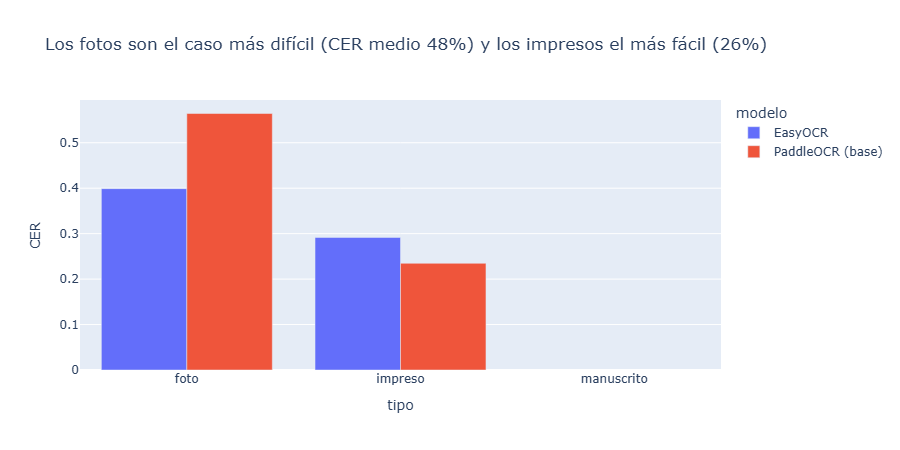

modelo,EasyOCR,PaddleOCR (base)
tipo,,
foto,0.399,0.564
impreso,0.292,0.235
manuscrito,NaN,NaN


In [9]:
por_tipo = pd.concat([base_doc, alt_doc]).groupby(["tipo", "modelo"]).CER.mean().reset_index()
peor = por_tipo.groupby("tipo").CER.mean()
if peor.isna().all():
    print("Sin referencias de documentos todavía: el gráfico de CER por tipo se genera al completar datos/referencias_documentos.csv")
else:
    fig = px.bar(por_tipo, x="tipo", y="CER", color="modelo", barmode="group",
                 title=f"Los {peor.idxmax()}s son el caso más difícil (CER medio {peor.max():.0%}) y los {peor.idxmin()}s el más fácil ({peor.min():.0%})")
    mostrar(fig, "g4_cer_por_tipo")
por_tipo.pivot(index="tipo", columns="modelo", values="CER").round(3)

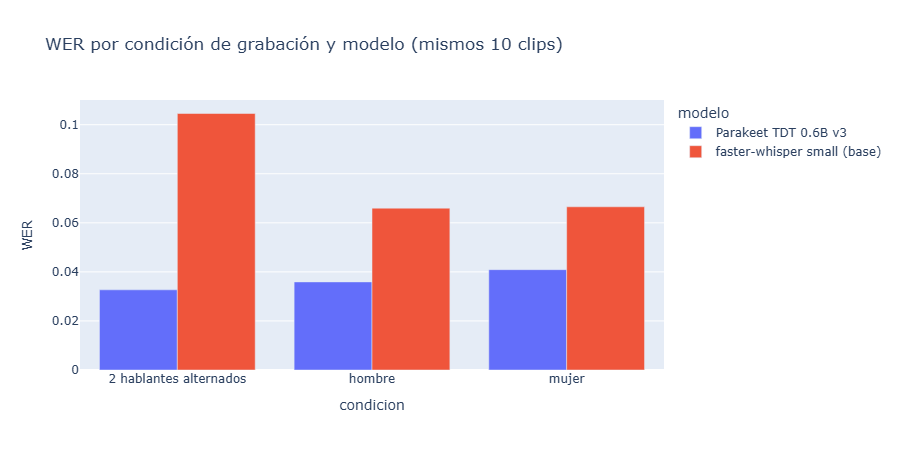

modelo,Parakeet TDT 0.6B v3,faster-whisper small (base)
condicion,,
2 hablantes alternados,0.033,0.105
hombre,0.036,0.066
mujer,0.041,0.067


In [10]:
w = pd.concat([base_aud, alt_aud]); w["condicion"] = w.condicion.str.split(",").str[-1].str.strip()
fig = px.bar(w.groupby(["condicion", "modelo"]).WER.mean().reset_index(), x="condicion", y="WER", color="modelo", barmode="group",
             title="WER por condición de grabación y modelo (mismos 10 clips)")
mostrar(fig, "g5_wer_por_condicion")
w.pivot_table(index="condicion", columns="modelo", values="WER").round(3)

In [11]:
# Audio con ruido de calle (sin referencia): revisión cualitativa de la entrevista en El Agustino
calle = aud[aud.condicion.str.contains("El Agustino|vendedora", regex=True)]
for r in calle.itertuples():
    print(f"── {r.id} ({r.duracion_seg:.0f} s, ruido de calle): {r.texto_asr[:600]}\n")

── clip_022 (136 s, ruido de calle): Buenos días, aquí son las 10 y 28 y estoy con una señora que va a darme su opinión acerca de partido de hoy. ¿Puedes decirme su nombre por favor? [PERSONA_1]. Mucho gusto, yo soy Jorge, soy alumno de la Universidad Nacional Mayor de San Marcos y le voy a hacer estas preguntas acerca del partido de hoy. ¿Qué expectativas tiene acerca de este partido? ¿Quién piensa que va a atacar más o a defender? Bueno, esperamos que Perú ganemos, ¿no? Espero que Padula, que eche goles. Muy bien, la siguiente pregunta es acerca de qué jugador piensa que va a ser más decisivo en este partido. Muy bien, y la ter

── clip_023 (189 s, ruido de calle): [HABLANTE_1] Buenos días profesor y compañeros. Hoy estoy cerca de aquí por mi casa y voy a [HABLANTE_1] hacer una entrevista acerca del fútbol como unión de masas. Estoy con las [HABLANTE_1] señoras. [PERSONA_2]. [PERSONA_3]. Muy bien, voy a comenzar con la primera [HABLANTE_1] pregunta y es ¿qué expectativas tienen ante 

## 6. Extracción estructurada con LLM (todos los documentos y clips)

In [12]:
regs = pd.concat([pd.DataFrame({"id": docs.id, "modalidad": "documento", "texto": docs.texto_ocr}),
                  pd.DataFrame({"id": aud.id, "modalidad": "audio", "texto": aud.texto_asr})])
ext = t2.extraer_llm(regs)
ext.to_csv("datos/extraccion_llm.csv", index=False)
print(ext.shape, "| modelo:", ext.modelo_llm.iloc[0])
print("Respuestas sin JSON válido:", ext.campos_json.str.contains('"error"').sum())
ext.head()

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Loading weights:   6%|▌         | 19/338 [00:00<00:02, 131.56it/s]

Loading weights:  10%|▉         | 33/338 [00:00<00:02, 128.82it/s]

Loading weights:  14%|█▎        | 46/338 [00:00<00:03, 92.21it/s] 

Loading weights:  29%|██▊       | 97/338 [00:00<00:01, 212.28it/s]

...

Loading weights:  56%|█████▌    | 190/338 [00:02<00:03, 46.75it/s]

Loading weights:  58%|█████▊    | 197/338 [00:02<00:02, 47.44it/s]

Loading weights: 100%|██████████| 338/338 [00:02<00:00, 131.74it/s]

(49, 5) | modelo: Qwen/Qwen2.5-1.5B-Instruct (transformers, CPU, greedy)
Respuestas sin JSON válido: 1


,id,modalidad,campos_json,modelo_llm,fecha
0,doc_001,documento,"{""modalidad"": ""documento"", ""tema"": ""Concurso Público para el Lema, Escudo, Bandera y Himno del Distrito de Mache"", ""...","Qwen/Qwen2.5-1.5B-Instruct (transformers, CPU, greedy)",2026-10-26
1,doc_002,documento,"{""modalidad"": ""documento"", ""tema"": ""Reserva Peru"", ""resumen"": ""El Banco Central de Reserva del Perú envía un mensaje...","Qwen/Qwen2.5-1.5B-Instruct (transformers, CPU, greedy)",2026-10-26
2,doc_003,documento,"{""modalidad"": ""document"", ""tema"": ""Toros y Diversiones Públicas"", ""resumen"": ""El texto describe cómo los toreros uti...","Qwen/Qwen2.5-1.5B-Instruct (transformers, CPU, greedy)",2026-10-26
3,doc_004,documento,"{""modalidad"": ""documento"", ""tema"": ""Barrido Chino Gas Helio Calle 10 Capon Backyardi 50"", ""resumen"": ""Documento sobr...","Qwen/Qwen2.5-1.5B-Instruct (transformers, CPU, greedy)",2026-10-26
4,doc_005,documento,"{""modalidad"": ""documento"", ""tema"": ""Perú"", ""resumen"": ""Documento sobre Perú."", ""emisor"": null, ""fecha"": null, ""monto...","Qwen/Qwen2.5-1.5B-Instruct (transformers, CPU, greedy)",2026-10-26


## 7. Auditoría humana de 20 extracciones al azar (10 documentos + 10 audios)
**Criterio:** una extracción es *completamente correcta* si (a) el JSON es válido y tiene solo las claves pedidas, (b) `tema` y `resumen` describen bien el texto, (c) todo dato presente (emisor, fecha, monto, citas, n.º de hablantes) aparece de verdad en el texto y (d) los datos ausentes van como `null`. Un solo campo inventado o equivocado la vuelve incorrecta. El estudiante revisa cada caso contra el texto y la imagen o el audio, y anota `correcto` (1/0) y `error` en `datos/auditoria_llm.csv`.

In [13]:
aud_csv = Path("datos/auditoria_llm.csv")
if not aud_csv.exists():
    m = pd.concat([ext[ext.modalidad == "documento"].sample(10, random_state=7), ext[ext.modalidad == "audio"].sample(10, random_state=7)])
    m.merge(regs[["id", "texto"]], on="id").assign(correcto="", error="")[["id", "modalidad", "texto", "campos_json", "correcto", "error"]].to_csv(aud_csv, index=False)
audit = pd.read_csv(aud_csv)
hechos = pd.to_numeric(audit.correcto, errors="coerce").notna().sum()
if hechos < 20:
    print(f"Auditoría pendiente: {hechos}/20 casos revisados. Completar la columna 'correcto' en datos/auditoria_llm.csv")
else:
    ok = int(pd.to_numeric(audit.correcto).sum())
    print(f"Acuerdo LLM-Humano: {ok}/20 ({ok/20:.0%})")
    print(audit.groupby("modalidad").correcto.sum().to_string())
    display(audit[pd.to_numeric(audit.correcto) == 0][["id", "modalidad", "error"]])
    pd.DataFrame([{"acuerdo": ok, "total": 20}]).to_csv("datos/auditoria_resumen.csv", index=False)

Auditoría pendiente: 0/20 casos revisados. Completar la columna 'correcto' en datos/auditoria_llm.csv


## 8. Decisión y reflexión

*(Esta sección se escribe después de ver las métricas de arriba; se completa con los números finales.)*

- **Documentos:** …
- **Audio:** …
- **Por tipo de documento:** …
- **Por tipo de audio:** …
- **Elección para un entorno real (precisión, costo y latencia):** …